## 🎮 Steam Game Data Visualization and Analysis

This notebook is part of a data visualization portfolio project exploring historical trends in Steam game data, sourced from [SteamDB.info](https://steamdb.info). The dataset includes detailed records of **game prices** and **concurrent player counts** over time.

### Project Objective

The goal of this analysis is to understand how the price and popularity of games evolve over time and how they might influence one another. Through data cleaning, aggregation, and visual exploration, we aim to uncover trends, spikes, and correlations that can offer insights into player behavior and market dynamics.

### 📊 What This Notebook Does

- **Price Analysis**
  - Aggregates and visualizes monthly trends for both the *final store price* and the *historical low price*.
  - Includes optional smoothing (e.g., rolling averages) to highlight long-term trends.

- **Player Count Analysis**
  - Visualizes daily and weekly average player counts with options for smoothing.
  - Highlights periods of growth, decline, and stability in player engagement.

- **Combined Visualizations**
  - Side-by-side plots for prices and players across multiple years.
  - Dual-axis plots for the same year, helping to identify how pricing strategies may have impacted player activity.

### 📌 Why This Matters

These visualizations provide a clear look into the life cycle of games—when interest peaks, how discounts affect player numbers, and whether player engagement aligns with pricing trends. It's a useful framework for game analysts, developers, and anyone interested in the economics of the Steam gaming ecosystem.



In this notebook I picked the game Rainbow Six Siege, but this same methodology can be applied to any steam game data downloaded from [SteamDB.info](https://steamdb.info)

In [1]:
import pandas as pd

from plots import (
    prepare_price_monthly,
    plot_monthly_prices,
    prepare_players_monthly,
    plot_daily_players,
    plot_weekly_players,
    plot_prices_and_players_side_by_side,
    plot_combined_price_players,
)

In [2]:
raw_price_df = pd.read_csv("data/rainbow six siege/prices.csv")
raw_players_df = pd.read_csv("data/rainbow six siege/player_counts.csv")

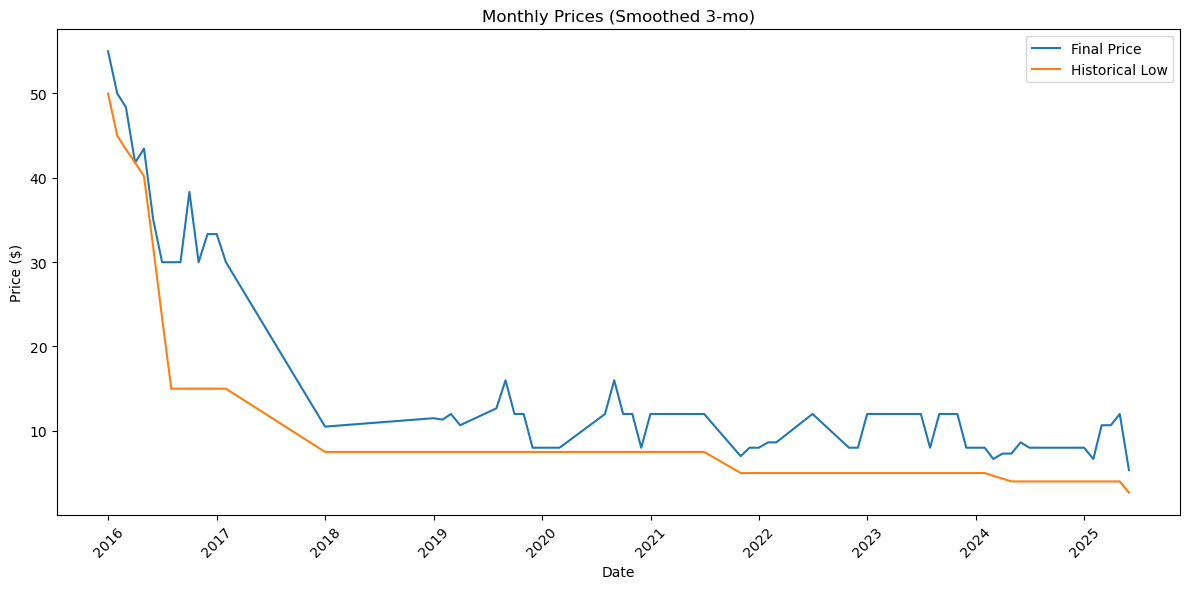

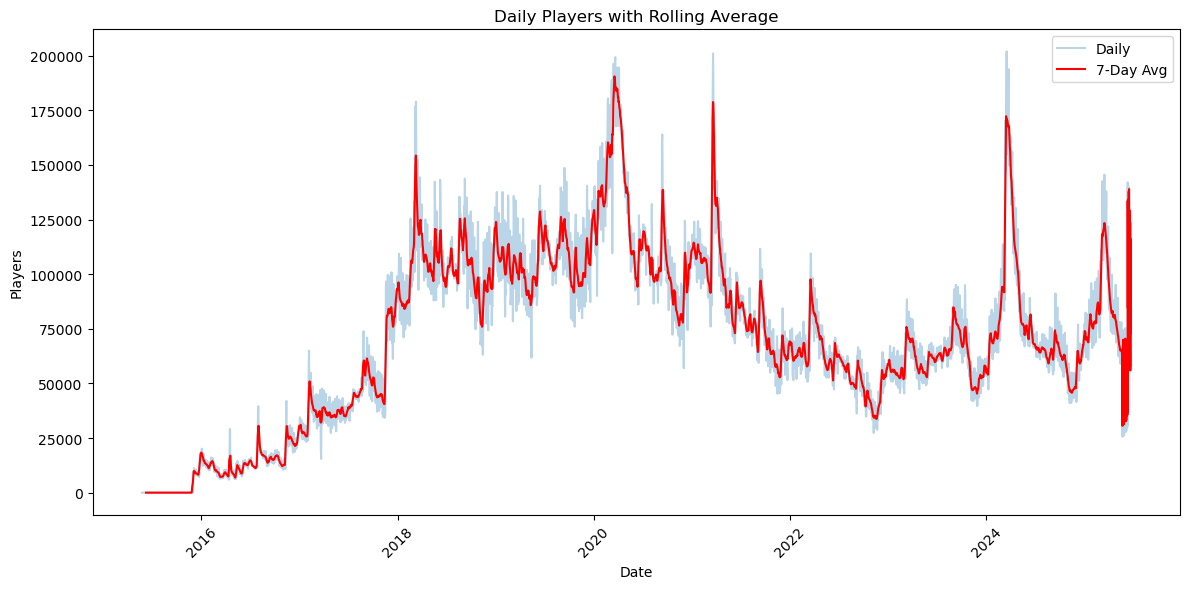

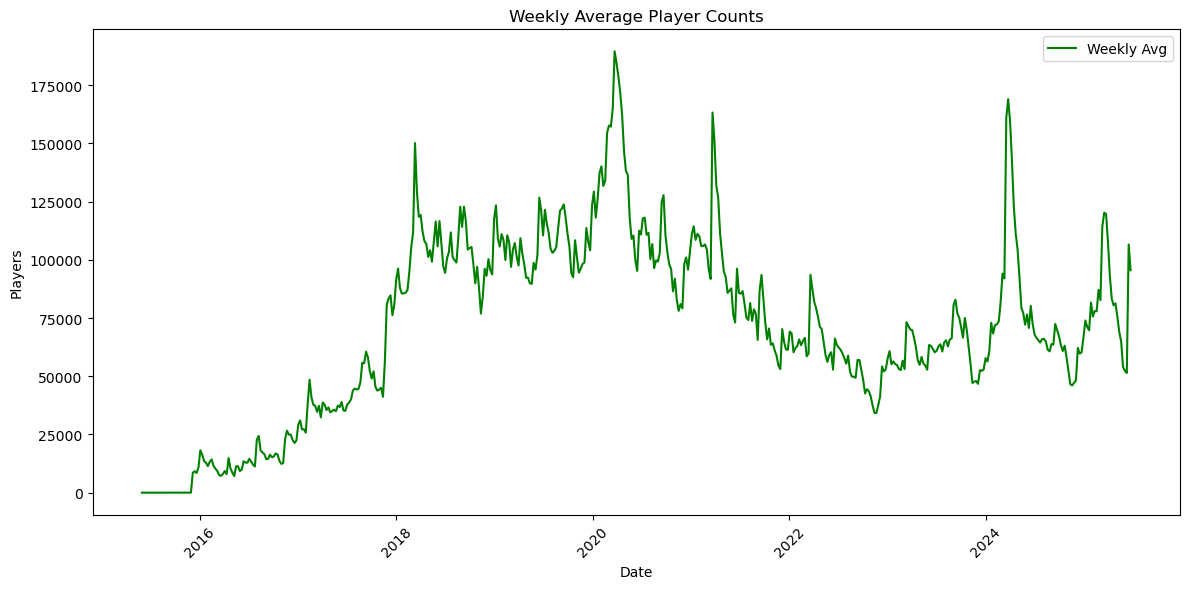

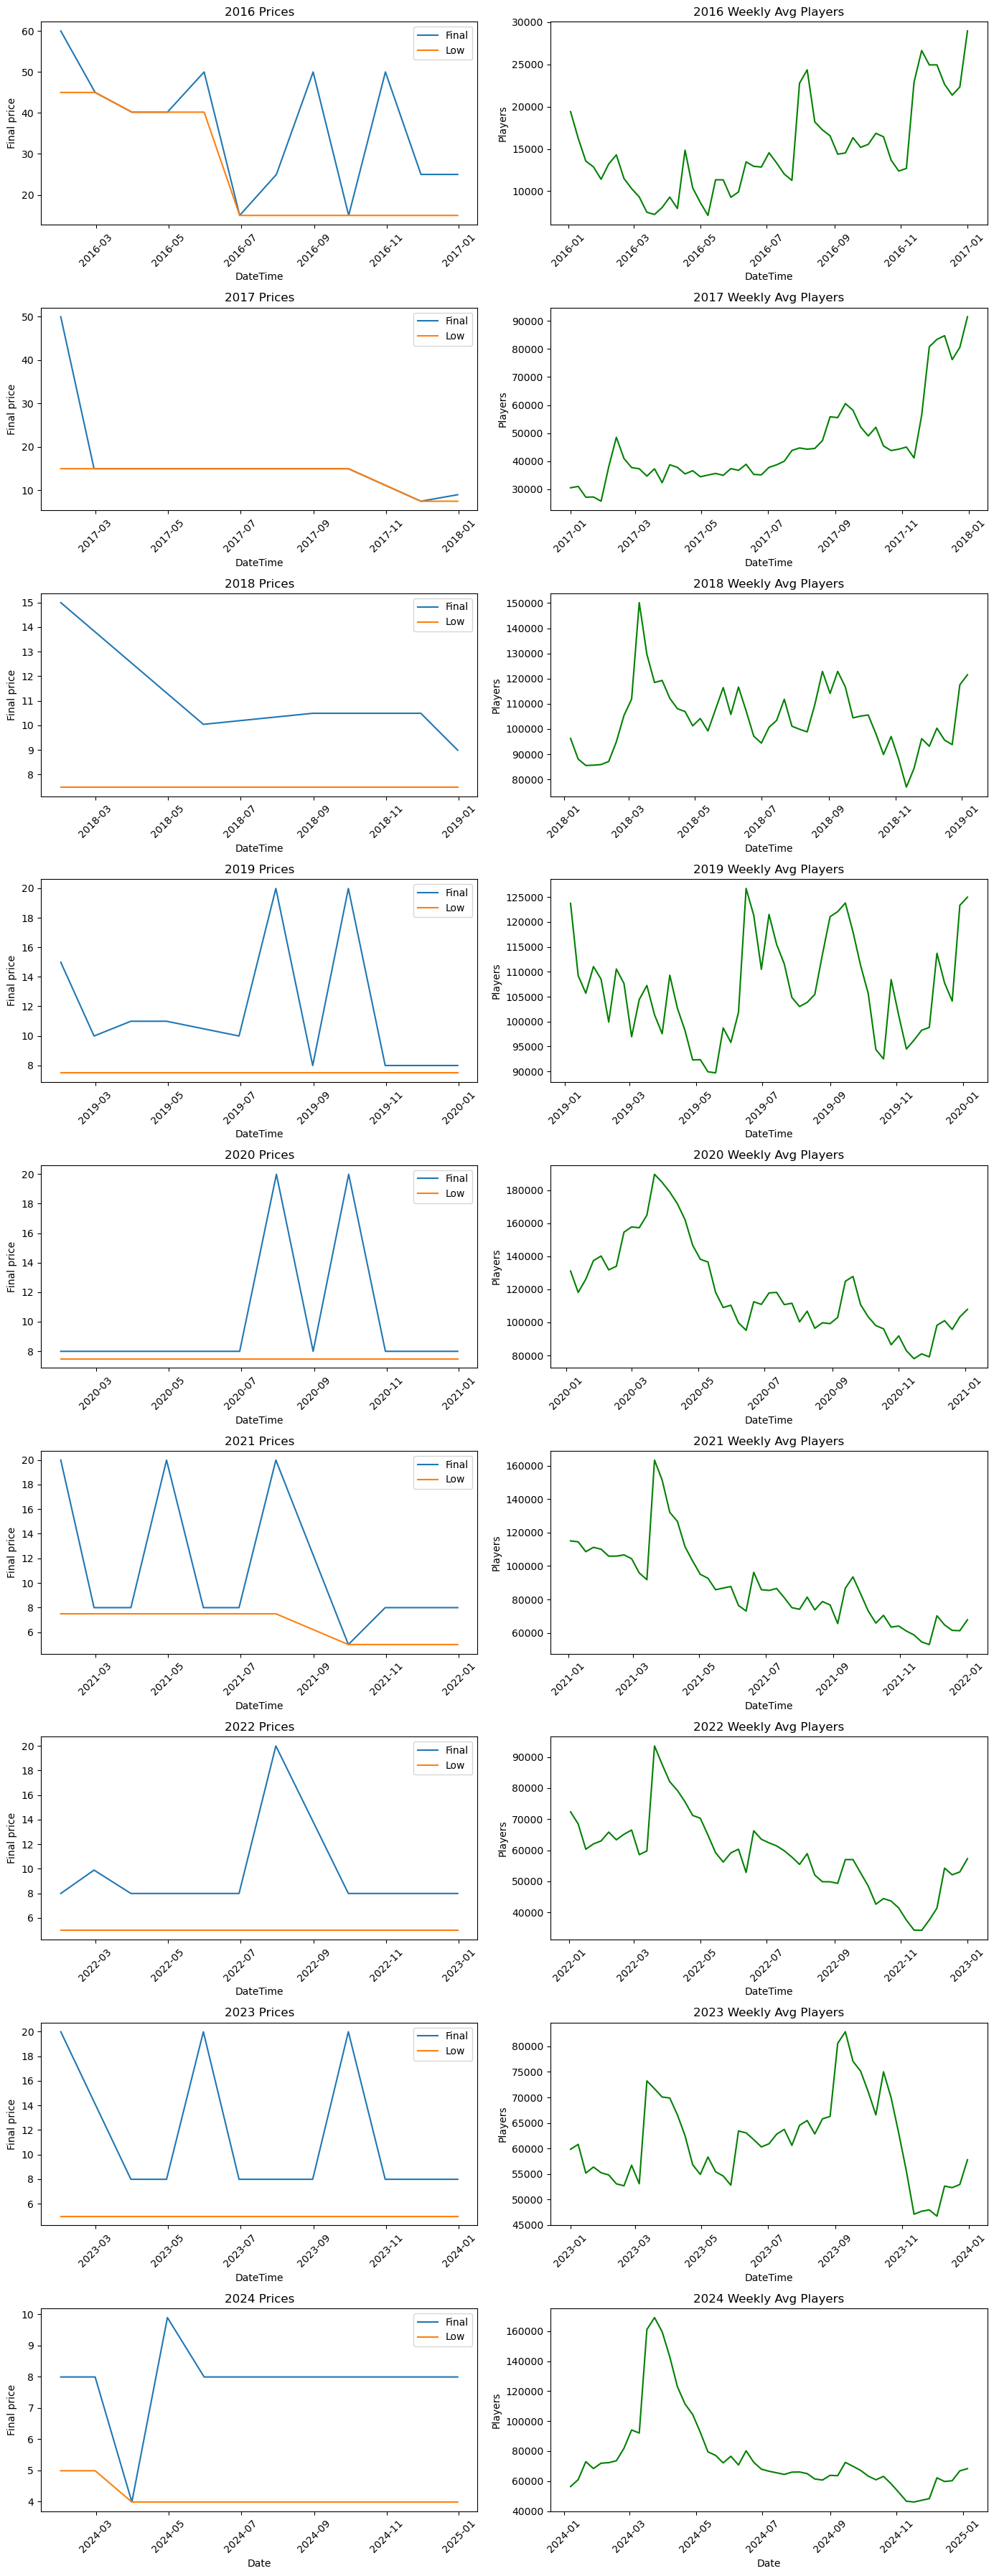

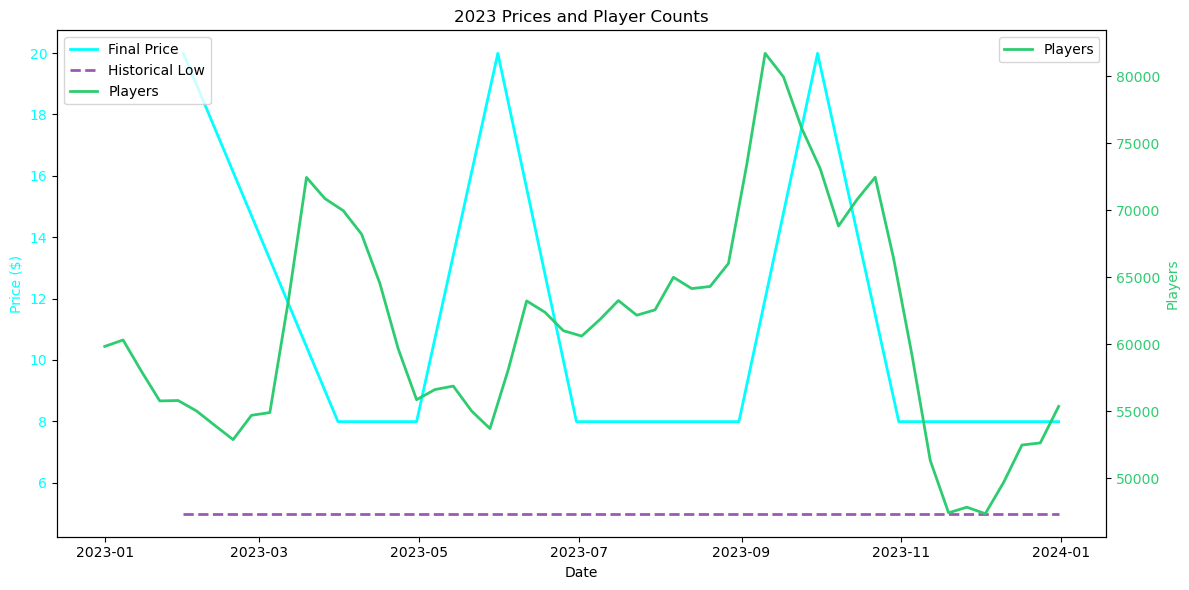

In [3]:
# ---- Parameters ----
price_date_col = "DateTime"
price_col = "Final price"
low_col = "Historical Low"
players_date_col = "DateTime"
players_col = "Players"
price_agg = "min"
years = list(range(2016, 2025))
rolling_price = 3
rolling_players = 7

# ---- 1. Plot Monthly Prices ----
monthly_price = prepare_price_monthly(
    raw_price_df,
    date_col=price_date_col,
    price_col=price_col,
    low_col=low_col,
    agg=price_agg
)
plot_monthly_prices(
    df=monthly_price,
    date_col=price_date_col,
    price_col=price_col,
    low_col=low_col,
    years=None,
    rolling=rolling_price
)

# ---- 2. Plot Daily Players (Smoothed) ----
plot_daily_players(
    raw_players_df,
    date_col=players_date_col,
    players_col=players_col,
    rolling=rolling_players
)

# ---- 3. Plot Weekly Average Players ----
plot_weekly_players(
    raw_players_df,
    date_col=players_date_col,
    players_col=players_col
)

# ---- 4. Plot Prices & Players Side-by-Side by Year ----
plot_prices_and_players_side_by_side(
    raw_price_df,
    raw_players_df,
    years=years,
    price_date=price_date_col,
    price_col=price_col,
    low_col=low_col,
    players_date=players_date_col,
    players_col=players_col,
    price_agg=price_agg
)

# ---- 5. Plot Combined Prices & Players for a Single Year ----
plot_combined_price_players(
    raw_price_df,
    raw_players_df,
    year=2023,  # Choose any year from your data
    price_date=price_date_col,
    price_col=price_col,
    low_col=low_col,
    players_date=players_date_col,
    players_col=players_col,
    price_agg=price_agg,
    smooth_players=True,
    smooth_window=2
)

## Analysis Focus: Rainbow Six Siege in 2023

The year 2023 was selected for analysis due to the unusually dynamic pricing behavior of Rainbow Six Siege during this period. 2023 featured multiple price fluctuations.pricing impacts player activity.

**Figure: Price and Player Trends in 2023**  
The chart above presents monthly final prices and historical lows (left axis) alongside weekly average player counts (right axis). Significant drops in price often coincide with short-term increases in player engagement, suggesting a strong correlation between discount periods and player interest.

### Key Observations

- Player activity tends to rise sharply during major sales, particularly when the final price reaches the historical low.
- Higher pricing periods generally correspond with declines in player count, indicating price sensitivity among the player base.
- The historical low remains constant throughout the year, suggesting that the game's discounting strategy relied on recurring rather than deeper price cuts.
- Engagement spikes driven by discounts are often temporary, pointing to the need for additional factors—such as content updates or events—for sustained player retention.

Overall, 2023 provides a strong case study for analyzing the effect of pricing strategies on user behavior in live-service games.
